# Title : Vortex Panel Method in 2D

**Submitted By**  

**Aathi Skantha Roopan T - SC26M001**

# Required packages

In [68]:
# do not change line below
from google.colab import files
# import required packages here
import numpy as np
import matplotlib.pyplot as plt
from numpy import sin, cos, pi, sqrt, arctan2
from numpy.linalg import solve

# Introduction

The vortex panel method is a numerical technique used to calculate the aerodynamic characteristics of two-dimensional airfoils and other bodies immersed in an inviscid, incompressible flow.

In this method, the surface of the body is divided into a finite number of straight-line panels. Vortex elements are distributed along these panels to represent the flow around the body.

The strength of the vortices determines the velocity field around the airfoil. By applying the no-penetration boundary condition at the control points and the Kutta condition at the trailing edge, a system of algebraic equations can be obtained and solved to determine the vortex strengths.

The pressure coefficient is then calculated using Bernoulli's equation.

Two formulations are considered in this study:

1. Constant-strength vortex panel method.
2. Linear-strength vortex panel method.

The methods are verified using a circular cylinder and tested on symmetric and cambered airfoils. Their convergence and limitations are also investigated.

**Assumptions**

The following assumptions are made in the vortex panel method:

1. The flow is two-dimensional.
2. The fluid is incompressible.
3. The flow is inviscid.
4. The flow is irrotational everywhere except at the vortex singularities.
5. The airfoil surface is impermeable.
6. The Kutta condition is applied at the trailing edge to obtain a physically meaningful circulation.

**Discretization of the body**

- The surface of the body is divided into N straight-line panels. 
- Each panel is defined by two consecutive nodal points.
- For panel j, the starting point is $(x_j, y_j)$ and the ending point is $(x_{j+1}, y_{j+1})$.
- The panel length is:
$$S_j=\sqrt{(x_{j+1}-x_j)^2+(y_{j+1}-y_j)^2}$$

- The panel inclination angle is:
$$\theta_j=\tan^{-1}\left(\frac{y_{j+1}-y_j}{x_{j+1}-x_j}\right)$$

- The control point is located at the midpoint of each panel:
$$x_{c,j}=\frac{x_j+x_{j+1}}{2}$$
$$y_{c,j}=\frac{y_j+y_{j+1}}{2}$$

The local coordinate system of each panel is used to calculate the induced velocity due to the vortex distribution.

The below code defines a function to calculate panel geometry : 

In [69]:
def panel_geometry(x, y):

    N = len(x) - 1

    dx = np.diff(x)
    dy = np.diff(y)

    S = np.sqrt(dx**2 + dy**2)

    theta = np.arctan2(dy, dx)

    xc = (x[:-1] + x[1:]) / 2
    yc = (y[:-1] + y[1:]) / 2

    return N, S, theta, xc, yc

**Boundary conditions**

The no-penetration boundary condition states that the normal component of velocity at the surface of the body must be zero.

Mathematically,

$$
\vec V \cdot \vec n=0
$$

where $\vec V$ is the total velocity and $\vec n$ is the outward unit normal vector.

The total velocity consists of the freestream velocity and the velocity induced by all vortex panels.

The Kutta condition requires the flow to leave the trailing edge smoothly.  

For a sharp trailing edge, this is commonly implemented by requiring the vortex strengths at the upper and lower trailing-edge endpoints to be equal in the linear formulation.

# Constant-strength vortex panel method

In the constant-strength vortex panel method, the vortex strength is assumed to remain constant over the entire length of each panel.

For panel j:
$$\gamma_j=\text{constant}$$


The unknown vortex strengths are determined by applying the no-penetration boundary condition at the control points.

The induced velocity at each control point is obtained by summing the contributions from all vortex panels.

The resulting equations can be written in matrix form as:
$$
[A]\{\gamma\}=\{b\}
$$

where:

- [A] is the influence coefficient matrix.
- {γ} is the vector of unknown vortex strengths.
- {b} represents the freestream velocity contribution.

After solving the linear system, the tangential velocity is calculated and the pressure coefficient is obtained from:

$$C_p=1-\left(\frac{V_t}{V_\infty}\right)^2$$


**Algorithm**  

1. Input the coordinates of the body surface and the number of panels.

2. Divide the body into straight-line panels.

3. Calculate the length, inclination angle and control point of each panel.

4. Calculate the unit normal and tangential directions.

5. Calculate the velocity influence coefficients of each vortex panel at every control point.

6. Construct the coefficient matrix using the no-penetration boundary condition.

7. Apply the Kutta condition at the trailing edge.

8. Solve the resulting system of linear algebraic equations to obtain the constant vortex strengths.

9. Calculate the tangential velocity at each control point.

10. Calculate the pressure coefficient using Bernoulli's equation.

11. Calculate the lift coefficient and plot the pressure coefficient distribution.

12. Return the vortex strengths, velocity and pressure coefficient.

**Mathematical formulation of influence coefficients**

**Velocity induced by a constant-strength vortex panel**

Consider a straight vortex panel of length $S_j$, having constant vortex strength $\gamma_j$.

The velocity induced at a point $x_i,y_i$ by a small vortex element is given by the Biot–Savart law:
$$
du=-\frac{\gamma_j}{2\pi}\frac{y_i-y}{(x_i-x)^2+(y_i-y)^2}ds
$$
$$
dv=\frac{\gamma_j}{2\pi}
\frac{x_i-x}{(x_i-x)^2+(y_i-y)^2}ds
$$

The total induced velocity is obtained by integrating along the panel:
$$
u_{ij}=-\frac{\gamma_j}{2\pi}\int_0^{S_j}\frac{y_i-y(s)}{r^2}ds
$$
$$
v_{ij}=\frac{\gamma_j}{2\pi}\int_0^{S_j}\frac{x_i-x(s)}{r^2}ds
$$

where
$$
r^2=(x_i-x(s))^2+(y_i-y(s))^2
$$

The total velocity at a control point is the sum of the freestream velocity and the velocities induced by all vortex panels.

The no-penetration condition is:
$$
V_{n,i}=0
$$

Therefore,
$$
\sum_{j=1}^{N} A_{ij}\gamma_j=-V_\infty\sin(\theta_i-\alpha)
$$

where $A_{ij}$ represents the normal velocity influence coefficient.

**Application of the Kutta condition**

or an airfoil with a sharp trailing edge, the Kutta condition requires the vortex strengths at the upper and lower trailing-edge panels to be equal and opposite:
$$
\gamma_1+\gamma_N=0
$$

For \(N\) constant-strength vortex panels, we have \(N\) unknowns. We use \(N-1\) no-penetration equations and one Kutta equation to obtain a square system:
$$
[A]\{\gamma\}=\{b\}
$$

The final row of the matrix represents the Kutta condition.

For a circular cylinder, there is no trailing edge. Instead, we impose zero net circulation:
$$
\Gamma=\sum_{j=1}^{N}\gamma_jS_j=0
$$

This ensures that the cylinder solution has no artificial circulation.

**Python implementation :**

In [70]:
def vortex_panel_method_0(x, y, V_inf=1.0, alpha=0.0,kutta=True):

    N = len(x) - 1

    # Panel geometry
    dx = np.diff(x)
    dy = np.diff(y)

    S = np.sqrt(dx**2 + dy**2)

    theta = np.arctan2(dy, dx)

    xc = (x[:-1] + x[1:]) / 2
    yc = (y[:-1] + y[1:]) / 2

    # Determine body orientation
    area = 0.5 * np.sum(
        x[:-1] * y[1:] - x[1:] * y[:-1]
    )

    orientation = 1 if area > 0 else -1

    # Outward unit normals
    nx = orientation * np.sin(theta)
    ny = -orientation * np.cos(theta)

    # Unit tangential vectors
    tx = np.cos(theta)
    ty = np.sin(theta)

    alpha = np.radians(alpha)

    U = V_inf * np.cos(alpha)
    V = V_inf * np.sin(alpha)

    # Numerical integration points
    nodes, weights = np.polynomial.legendre.leggauss(24)

    nodes = (nodes + 1) / 2
    weights = weights / 2

    # Influence coefficient matrix
    A = np.zeros((N, N))

    for i in range(N):

        for j in range(N):

            # Self-panel normal influence
            if i == j:
                A[i, j] = 0.0
                continue

            # Source points along panel j
            xs = x[j] + nodes * dx[j]
            ys = y[j] + nodes * dy[j]

            rx = xc[i] - xs
            ry = yc[i] - ys

            r2 = rx**2 + ry**2

            # Induced velocity per unit vortex strength
            u = np.sum(weights * (-ry / r2)) / (2 * np.pi) * S[j]

            v = np.sum(weights * (rx / r2)) / (2 * np.pi) * S[j]

            A[i, j] = u * nx[i] + v * ny[i]

    # Freestream normal velocity
    rhs = -(U * nx + V * ny)

    # Apply trailing-edge Kutta condition
    if kutta:

        A[-1, :] = 0.0
        A[-1, 0] = 1.0
        A[-1, -1] = 1.0

        rhs[-1] = 0.0

    # For a cylinder, impose zero net circulation
    else:

        A[-1, :] = S
        rhs[-1] = 0.0

    # Solve for vortex strengths
    gamma = np.linalg.solve(A, rhs)

    # Calculate tangential velocities
    Vt = U * tx + V * ty

    for i in range(N):

        for j in range(N):

            if i == j:

                Vt[i] += orientation * gamma[j] / 2

            else:

                xs = x[j] + nodes * dx[j]
                ys = y[j] + nodes * dy[j]

                rx = xc[i] - xs
                ry = yc[i] - ys

                r2 = rx**2 + ry**2

                u = np.sum(weights * (-ry / r2)) / (2 * np.pi) * S[j]

                v = np.sum(weights * (rx / r2)) / (2 * np.pi) * S[j]

                Vt[i] += gamma[j] * (u * tx[i] + v * ty[i])

    # Pressure coefficient
    Cp = 1 - (Vt / V_inf)**2

    # Total circulation
    circulation = np.sum(gamma * S)

    # Lift coefficient
    chord = np.max(x) - np.min(x)

    Cl = -2 * circulation / (V_inf * chord)

    return {
        "gamma": gamma,
        "Vt": Vt,
        "Cp": Cp,
        "Cl": Cl,
        "circulation": circulation,
        "xc": xc,
        "yc": yc,
        "S": S,
        "theta": theta
    }

# Linear-strength vortex panel method

In the linear-strength vortex panel method, the vortex strength is assumed to vary linearly between the two endpoints of each panel.

For panel $j$, the vortex strength is expressed as:
$$
\gamma_j(s)=\gamma_j+
\frac{s}{S_j}(\gamma_{j+1}-\gamma_j)
$$

where:
- $\gamma_j$ is the vortex strength at the starting endpoint.
- $\gamma_{j+1}$ is the vortex strength at the ending endpoint.
- $S_j$ is the panel length.
- $s$ is the distance measured along the panel.
The vortex strength is continuous between adjacent panels because they share a common endpoint value.

For $N$ panels, there are $N+1$ unknown nodal vortex strengths.

The unknowns are determined by applying the no-penetration condition at the $N$ control points and the Kutta condition at the trailing edge.

The final system contains $N+1$ equations.

The Kutta condition is:
$$
\boxed{\gamma_1+\gamma_{N+1}=0}
$$

The resulting vortex strengths are used to calculate tangential velocity and pressure coefficient.

**Algorithm**

1. Input the coordinates of the body surface and the number of panels.
2. Divide the body surface into straight-line panels.
3. Calculate the length, inclination angle and midpoint of each panel.
4. Define the vortex strength at each panel endpoint.
5. Assume that vortex strength varies linearly between adjacent endpoints.
6. Calculate the normal and tangential velocity influence coefficients using the Biot–Savart law.
7. Assemble the influence coefficient matrix using the no-penetration boundary condition at all control points.
8. Apply the Kutta condition at the trailing edge to obtain the additional equation.
9. Solve the resulting system of N+1 simultaneous equations to determine the nodal vortex strengths.
10. Calculate the tangential velocity at each control point.
11. Calculate the pressure coefficient using Bernoulli's equation.
12. Integrate the pressure distribution to obtain the lift coefficient.
13. Return the nodal vortex strengths, velocity, pressure coefficient and lift coefficient.

**Mathematical formulation of influence coefficients**

**Influence coefficients for linear-strength panels**

The velocity induced by a vortex distribution is obtained by integrating the Biot–Savart law along each panel.

The linear vortex distribution can be expressed using two linear interpolation functions:
$$
N_1(s)=1-\frac{s}{S_j}
$$

$$
N_2(s)=\frac{s}{S_j}
$$

Therefore,
$$
\gamma_j(s)=N_1(s)\gamma_j+N_2(s)\gamma_{j+1}
$$

The induced velocity is calculated by integrating the contributions associated with both endpoint strengths.

At each control point, the normal velocity must satisfy:
$$
V_{n,i}=0
$$

Combining the contributions from all panels gives:
$$
\sum_{j=1}^{N+1} A_{ij}\gamma_j=-V_\infty\vec e_\infty\cdot\vec n_i
$$

The Kutta condition provides the final equation:
$$
\gamma_1+\gamma_{N+1}=0
$$

Thus, the system can be represented as:
$$
[A]\{\gamma\}=\{b\}
$$

The system is solved to obtain all nodal vortex strengths.

**Python implementation :**

In [71]:
def vortex_panel_method_1(x, y, V_inf=1.0, alpha=0.0,kutta=True):

    """
    Linear-strength vortex panel method.

    Parameters
    ----------
    x, y : arrays
        Coordinates of body surface nodes.
    V_inf : float
        Freestream velocity.
    alpha : float
        Angle of attack in degrees.
    kutta : bool
        True for airfoil, False for circular cylinder.

    Returns
    -------
    Dictionary containing nodal vortex strengths,
    tangential velocities, Cp and lift coefficient.
    """

    # Number of panels
    N = len(x) - 1

    # Panel geometry
    dx = np.diff(x)
    dy = np.diff(y)

    S = np.sqrt(dx**2 + dy**2)

    theta = np.arctan2(dy, dx)

    xc = (x[:-1] + x[1:]) / 2
    yc = (y[:-1] + y[1:]) / 2

    # Determine orientation
    area = 0.5 * np.sum(x[:-1] * y[1:] - x[1:] * y[:-1])

    orientation = 1 if area > 0 else -1

    # Outward normal vectors
    nx = orientation * np.sin(theta)
    ny = -orientation * np.cos(theta)

    # Tangential vectors
    tx = np.cos(theta)
    ty = np.sin(theta)

    # Freestream velocity components
    alpha = np.radians(alpha)

    U = V_inf * np.cos(alpha)
    V = V_inf * np.sin(alpha)

    # Gaussian quadrature
    nodes, weights = np.polynomial.legendre.leggauss(32)

    nodes = (nodes + 1) / 2
    weights = weights / 2

    # Influence matrices
    An = np.zeros((N, N+1))
    At = np.zeros((N, N+1))

    for i in range(N):
        
        for j in range(N):

            # Self-panel influence
            if i == j:

                At[i, j] += orientation / 4
                At[i, j+1] += orientation / 4

                continue

            # Integration points on panel j
            xs = x[j] + nodes * dx[j]
            ys = y[j] + nodes * dy[j]

            rx = xc[i] - xs
            ry = yc[i] - ys

            r2 = rx**2 + ry**2

            # Linear interpolation functions
            N1 = 1 - nodes
            N2 = nodes

            # Velocity influence of first endpoint
            u1 = np.sum(weights * N1 * (-ry / r2)) * S[j] / (2*pi)

            v1 = np.sum(weights * N1 * (rx / r2)) * S[j] / (2*pi)

            # Velocity influence of second endpoint
            u2 = np.sum(weights * N2 * (-ry / r2)) * S[j] / (2*pi)

            v2 = np.sum(weights * N2 * (rx / r2)) * S[j] / (2*pi)

            # Normal influence coefficients
            An[i, j] += u1*nx[i] + v1*ny[i]
            An[i, j+1] += u2*nx[i] + v2*ny[i]

            # Tangential influence coefficients
            At[i, j] += u1*tx[i] + v1*ty[i]
            At[i, j+1] += u2*tx[i] + v2*ty[i]

    # Freestream normal velocity
    rhs = -(U*nx + V*ny)

    # Construct complete system
    A = np.zeros((N+1, N+1))
    b = np.zeros(N+1)

    A[:N, :] = An
    b[:N] = rhs

    # Apply trailing-edge Kutta condition
    if kutta:

        A[N, 0] = 1
        A[N, N] = 1

    # For cylinder: impose zero circulation
    else:

        for j in range(N):

            A[N, j] += S[j] / 2
            A[N, j+1] += S[j] / 2

    # Solve for nodal vortex strengths
    gamma = np.linalg.solve(A, b)

    # Tangential velocity
    Vt = U*tx + V*ty + At @ gamma

    # Pressure coefficient
    Cp = 1 - (Vt/V_inf)**2

    # Pressure force integration
    Fx = -np.sum(Cp * nx * S)
    Fy = -np.sum(Cp * ny * S)

    # Lift coefficient
    chord = np.max(x) - np.min(x)

    Cl = (-Fx*np.sin(alpha) + Fy*np.cos(alpha))/(V_inf**2*chord)

    # Total circulation
    circulation = np.sum(S * (gamma[:-1] + gamma[1:]) / 2)

    return {
        "gamma": gamma,
        "Vt": Vt,
        "Cp": Cp,
        "Cl": Cl,
        "circulation": circulation,
        "xc": xc,
        "yc": yc,
        "S": S,
        "theta": theta
    }

# Verification of vortex panel methods on circular cylinder

For a circular cylinder of radius \(R\), the theoretical pressure coefficient is:
$$
C_p=1-4\sin^2\theta
$$

where $\theta$ is the angular position measured from the positive x-axis.

The numerical results obtained from both vortex panel methods are compared with this analytical solution.

**Generate cylinder coordinates :**

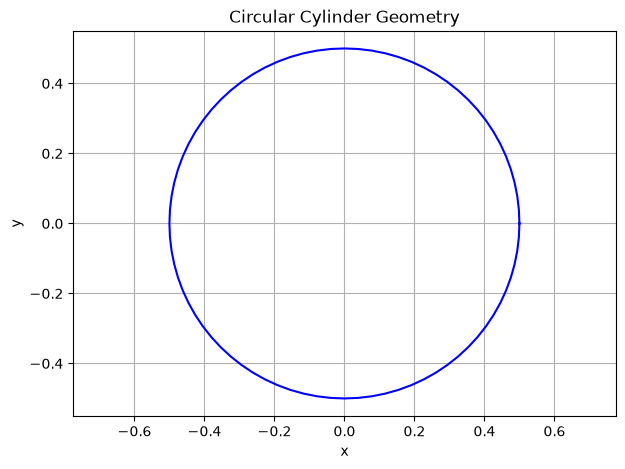

In [72]:
# Cylinder parameters
R = 0.5
N = 80

# Angular coordinates
angle = np.linspace(0, 2*np.pi, N+1)

# Cylinder coordinates
x_cylinder = R*np.cos(angle)
y_cylinder = R*np.sin(angle)

# Plot cylinder
plt.figure(figsize=(7,5))

plt.plot(x_cylinder, y_cylinder, 'b-')

plt.axis('equal')
plt.xlabel("x")
plt.ylabel("y")
plt.title("Circular Cylinder Geometry")
plt.grid()

plt.show()

In [73]:
# Freestream conditions
V_inf = 1.0
alpha = 0.0

# Constant-strength method
result_0 = vortex_panel_method_0(
    x_cylinder,
    y_cylinder,
    V_inf,
    alpha,
    kutta=False
)

# Linear-strength method
result_1 = vortex_panel_method_1(
    x_cylinder,
    y_cylinder,
    V_inf,
    alpha,
    kutta=False
)

print("Constant-strength Cl:", result_0["Cl"])
print("Linear-strength Cl:", result_1["Cl"])

print("Constant-strength circulation:",
      result_0["circulation"])

print("Linear-strength circulation:",
      result_1["circulation"])

Constant-strength Cl: 8.604228440844963e-16
Linear-strength Cl: 5.530840542500304e-15
Constant-strength circulation: -4.3021142204224816e-16
Linear-strength circulation: -2.546574062733953e-15


**Analytical and numerical pressure coefficients :**

In [74]:
# Control point angular positions
theta_c = np.arctan2(
    result_0["yc"],
    result_0["xc"]
)

# Analytical Cp
Cp_exact = 1 - 4*np.sin(theta_c)**2

# RMS errors
error_0 = np.sqrt(
    np.mean((result_0["Cp"] - Cp_exact)**2)
)

error_1 = np.sqrt(
    np.mean((result_1["Cp"] - Cp_exact)**2)
)

print("Constant-strength RMS error:", error_0)
print("Linear-strength RMS error:", error_1)

Constant-strength RMS error: 0.22227618761438286
Linear-strength RMS error: 0.018004247149896242


**Plot comparison ($\theta$ vs $C_p$)**

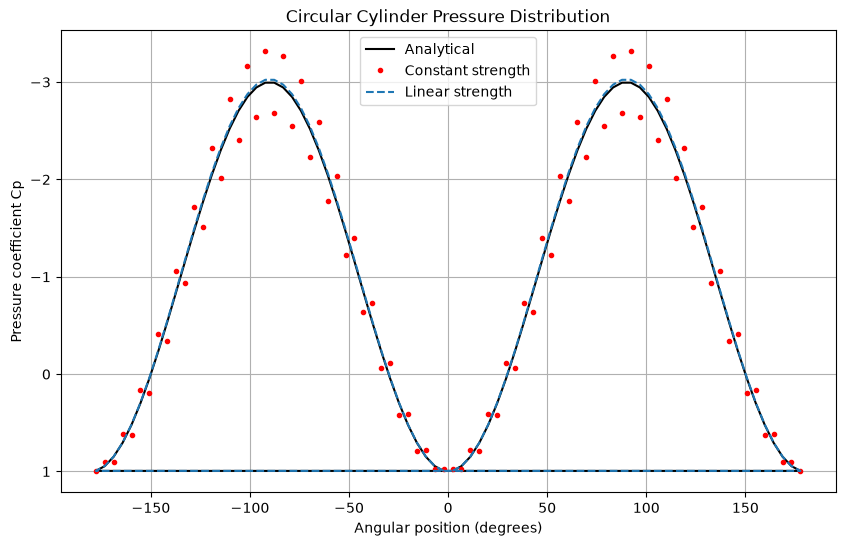

In [75]:
plt.figure(figsize=(10,6))

plt.plot(
    np.degrees(theta_c),
    Cp_exact,
    'k-',
    label="Analytical"
)

plt.plot(
    np.degrees(theta_c),
    result_0["Cp"],
    'ro',
    markersize=3,
    label="Constant strength"
)

plt.plot(
    np.degrees(theta_c),
    result_1["Cp"],
    '--',
    markersize=3,
    label="Linear strength"
)

plt.xlabel("Angular position (degrees)")
plt.ylabel("Pressure coefficient Cp")
plt.title("Circular Cylinder Pressure Distribution")
plt.gca().invert_yaxis()
plt.grid()
plt.legend()
plt.show()

# Convergence Study

In [76]:
panel_numbers = [20, 40, 80, 160]

error_constant = []
error_linear = []

for N in panel_numbers:

    angle = np.linspace(0, 2*np.pi, N+1)

    x = R * np.cos(angle)
    y = R * np.sin(angle)

    # Constant-strength method
    res0 = vortex_panel_method_0(
        x, y, V_inf=1.0, alpha=0.0,
        kutta=False
    )

    # Linear-strength method
    res1 = vortex_panel_method_1(
        x, y, V_inf=1.0, alpha=0.0,
        kutta=False
    )

    # Analytical solution
    theta = np.arctan2(res0["yc"], res0["xc"])

    Cp_exact = 1 - 4*np.sin(theta)**2

    # Calculate errors
    e0 = np.sqrt(np.mean((res0["Cp"] - Cp_exact)**2))
    e1 = np.sqrt(np.mean((res1["Cp"] - Cp_exact)**2))

    error_constant.append(e0)
    error_linear.append(e1)

    print("Number of panels:", N)
    print("Constant-strength error:", e0)
    print("Linear-strength error:", e1)
    print("Constant-strength Cl:", res0["Cl"])
    print("Linear-strength Cl:", res1["Cl"])

Number of panels: 20
Constant-strength error: 1.6570805705857976
Linear-strength error: 0.06085060184592654
Constant-strength Cl: 5.551115123125783e-16
Linear-strength Cl: 1.6341095143701523e-15
Number of panels: 40
Constant-strength error: 0.5803305012156891
Linear-strength error: 0.03429712904202443
Constant-strength Cl: -1.3322676295501878e-15
Linear-strength Cl: -8.040443311152501e-16
Number of panels: 80
Constant-strength error: 0.22227618761438286
Linear-strength error: 0.018004247149896242
Constant-strength Cl: 8.604228440844963e-16
Linear-strength Cl: 5.530840542500304e-15
Number of panels: 160
Constant-strength error: 4.241765506435391
Linear-strength error: 0.009202961788873228
Constant-strength Cl: 1.4210854715202004e-14
Linear-strength Cl: 8.881784197001252e-16


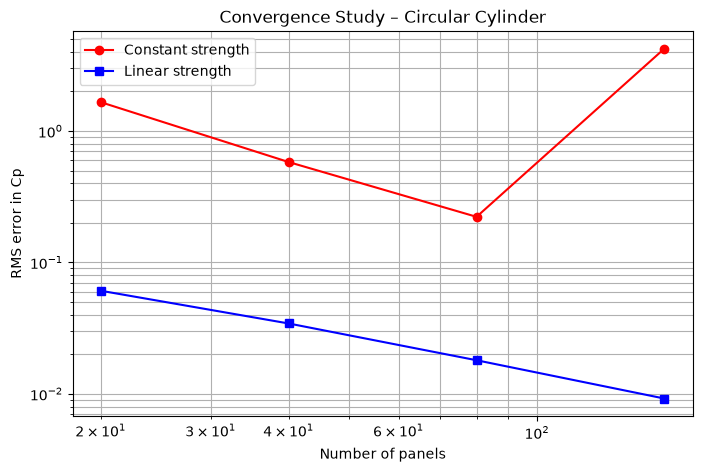

In [77]:
plt.figure(figsize=(8,5))

plt.loglog(
    panel_numbers,
    error_constant,
    'ro-',
    label="Constant strength"
)

plt.loglog(
    panel_numbers,
    error_linear,
    'bs-',
    label="Linear strength"
)

plt.xlabel("Number of panels")
plt.ylabel("RMS error in Cp")
plt.title("Convergence Study – Circular Cylinder")
plt.grid(True,which="both")
plt.legend()
plt.show()

The constant-strength and linear-strength vortex panel methods were tested on a circular cylinder. The numerical pressure coefficient distributions were compared with the analytical potential-flow solution.

The RMS error was used to measure the difference between the numerical and analytical pressure coefficients.

The initial calculation with 80 panels produced an RMS error of 0.22228 for the constant-strength method and 0.01800 for the linear-strength method.

The convergence study investigates how the accuracy of each method changes with increasing panel numbers. The results are also examined using the predicted lift coefficient and total circulation.

# Verification of Vortex Panel Methods on Airfoils (Symmetric and Non-Symmetric)

The vortex panel methods are tested using two NACA airfoils:

1. $NACA$ $0012$ – a symmetric airfoil with 12% thickness.
2. $NACA$ $4412$ – a cambered airfoil with 12% thickness.

The pressure coefficient distributions obtained using constant-strength and linear-strength vortex panel methods will be compared.

**Generate NACA 4-digit airfoil coordinates**

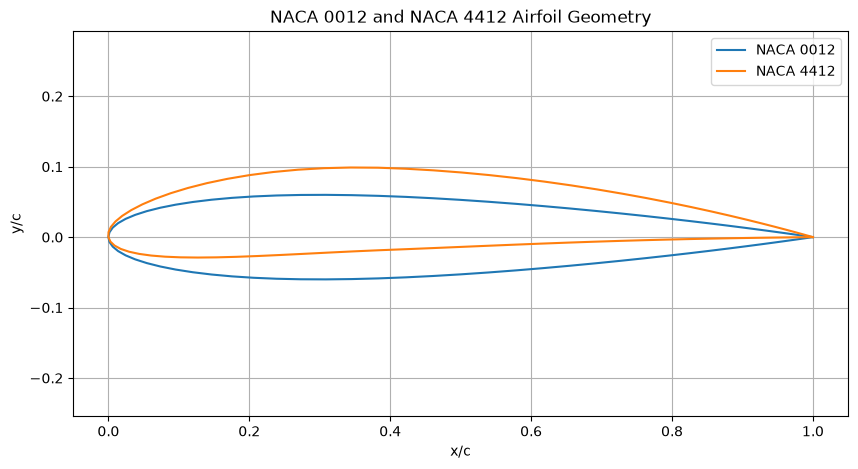

In [78]:
def naca4(m, p, t, n=41):

    beta = np.linspace(0, np.pi, n)
    x = (1 - np.cos(beta)) / 2

    yt = 5 * t * (0.2969 * np.sqrt(x) - 0.1260 * x - 0.3516 * x**2 + 0.2843 * x**3 - 0.1036 * x**4)

    yc = np.zeros_like(x)
    dyc_dx = np.zeros_like(x)

    for i in range(n):

        if x[i] < p and p != 0:
            yc[i] = (m / p**2) * (2*p*x[i] - x[i]**2)

            dyc_dx[i] = (2*m / p**2) * (p - x[i])

        elif p != 0:
            yc[i] = (m / (1-p)**2) * ((1 - 2*p) + 2*p*x[i] - x[i]**2)

            dyc_dx[i] = (2*m / (1-p)**2) * (p - x[i])

    theta = np.arctan(dyc_dx)

    xu = x - yt * np.sin(theta)
    yu = yc + yt * np.cos(theta)

    xl = x + yt * np.sin(theta)
    yl = yc - yt * np.cos(theta)

    x_coordinates = np.concatenate((xu[::-1], xl[1:]))
    y_coordinates = np.concatenate((yu[::-1], yl[1:]))

    return x_coordinates, y_coordinates

# NACA 0012: symmetric airfoil
x0012, y0012 = naca4(0.0, 0.0, 0.12)

# NACA 4412: cambered airfoil
x4412, y4412 = naca4(0.04, 0.4, 0.12)

plt.figure(figsize=(10, 5))

plt.plot(x0012, y0012, label="NACA 0012")
plt.plot(x4412, y4412, label="NACA 4412")

plt.xlabel("x/c")
plt.ylabel("y/c")
plt.title("NACA 0012 and NACA 4412 Airfoil Geometry")
plt.axis("equal")
plt.grid()
plt.legend()
plt.show()    

**Apply constant-strength and linear-strength methods**

In [79]:
# Freestream conditions
V_inf = 1.0
alpha = 5.0

# NACA 0012
result_0012_0 = vortex_panel_method_0(x0012, y0012, V_inf, alpha)
result_0012_1 = vortex_panel_method_1(x0012, y0012, V_inf, alpha)

# NACA 4412
result_4412_0 = vortex_panel_method_0(x4412, y4412, V_inf, alpha)
result_4412_1 = vortex_panel_method_1(x4412, y4412, V_inf, alpha)

print("NACA 0012")
print("Constant-strength Cl:", result_0012_0["Cl"])
print("Linear-strength Cl:", result_0012_1["Cl"])

print("\nNACA 4412")
print("Constant-strength Cl:", result_4412_0["Cl"])
print("Linear-strength Cl:", result_4412_1["Cl"])

NACA 0012
Constant-strength Cl: 0.6050667328823804
Linear-strength Cl: 0.6052888999146758

NACA 4412
Constant-strength Cl: 1.1123805412558938
Linear-strength Cl: 1.122486977079316


**Plot pressure coefficient distributions**

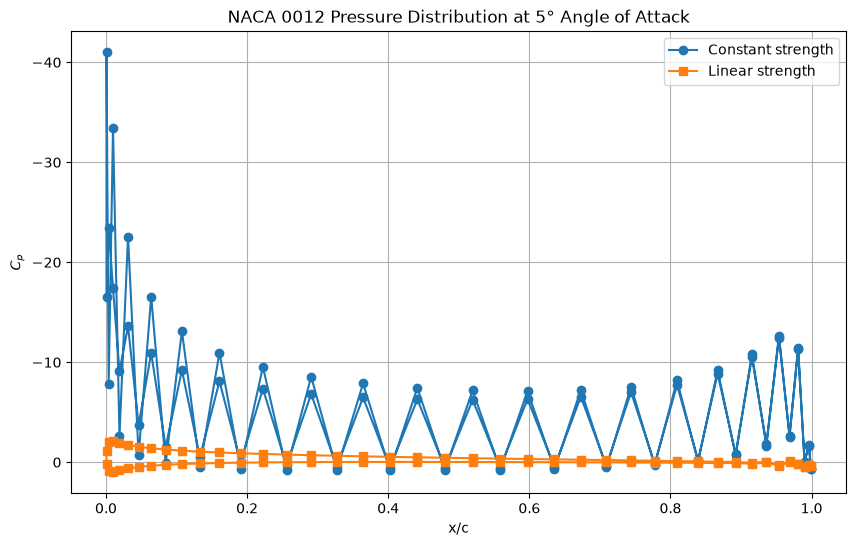

In [80]:
plt.figure(figsize=(10, 6))

plt.plot(result_0012_0["xc"], result_0012_0["Cp"],
         "o-", label="Constant strength")

plt.plot(result_0012_1["xc"], result_0012_1["Cp"],
         "s-", label="Linear strength")

plt.xlabel("x/c")
plt.ylabel("$C_p$")
plt.title("NACA 0012 Pressure Distribution at 5° Angle of Attack")
plt.gca().invert_yaxis()
plt.grid()
plt.legend()
plt.show()

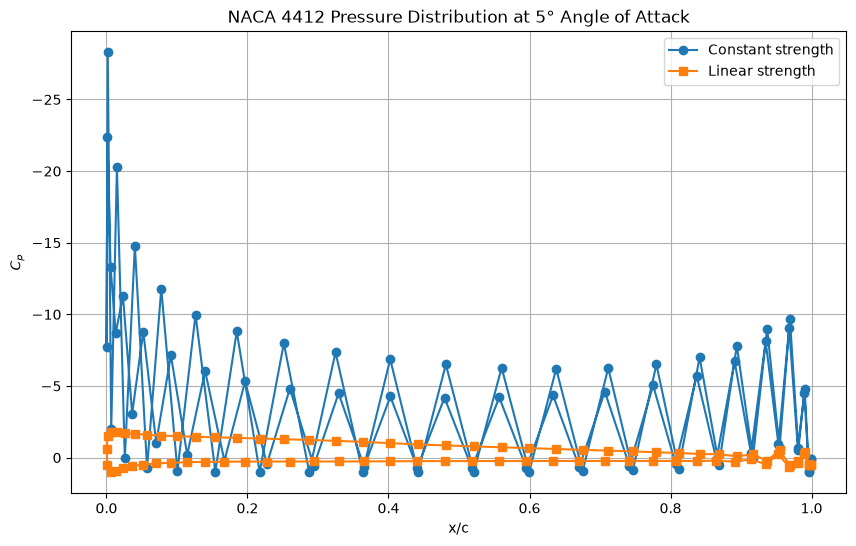

In [81]:
plt.figure(figsize=(10, 6))

plt.plot(result_4412_0["xc"], result_4412_0["Cp"],
         "o-", label="Constant strength")

plt.plot(result_4412_1["xc"], result_4412_1["Cp"],
         "s-", label="Linear strength")

plt.xlabel("x/c")
plt.ylabel("$C_p$")
plt.title("NACA 4412 Pressure Distribution at 5° Angle of Attack")
plt.gca().invert_yaxis()
plt.grid()
plt.legend()
plt.show()

**Plot upper and lower surfaces separately**

In [82]:
def plot_separate_surfaces(result, title):

    N = len(result["Cp"])
    mid = N // 2

    plt.figure(figsize=(10, 6))

    # Upper surface
    upper_x = result["xc"][:mid]
    upper_cp = result["Cp"][:mid]

    order = np.argsort(upper_x)

    plt.plot(upper_x[order], upper_cp[order],
             "o-", label="Upper surface")

    # Lower surface
    lower_x = result["xc"][mid:]
    lower_cp = result["Cp"][mid:]

    order = np.argsort(lower_x)

    plt.plot(lower_x[order], lower_cp[order],
             "s-", label="Lower surface")

    plt.xlabel("x/c")
    plt.ylabel("$C_p$")
    plt.title(title)
    plt.gca().invert_yaxis()
    plt.grid()
    plt.legend()
    plt.show()

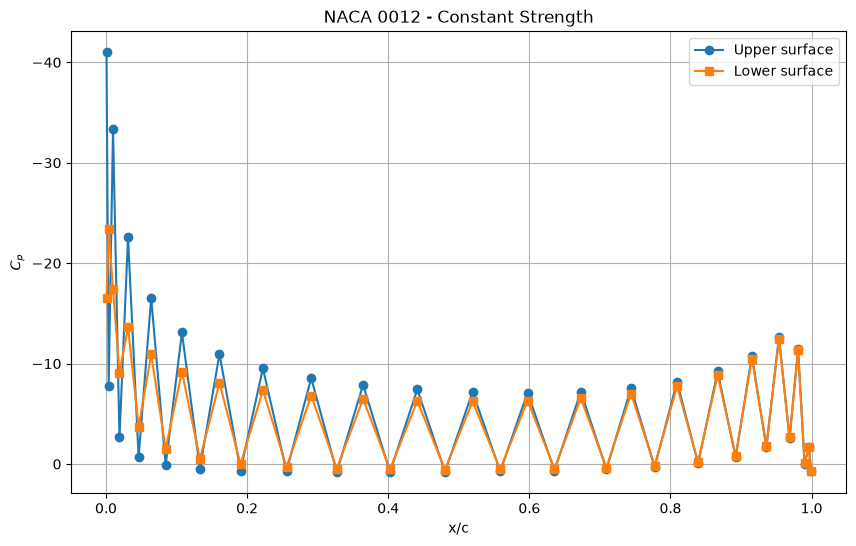

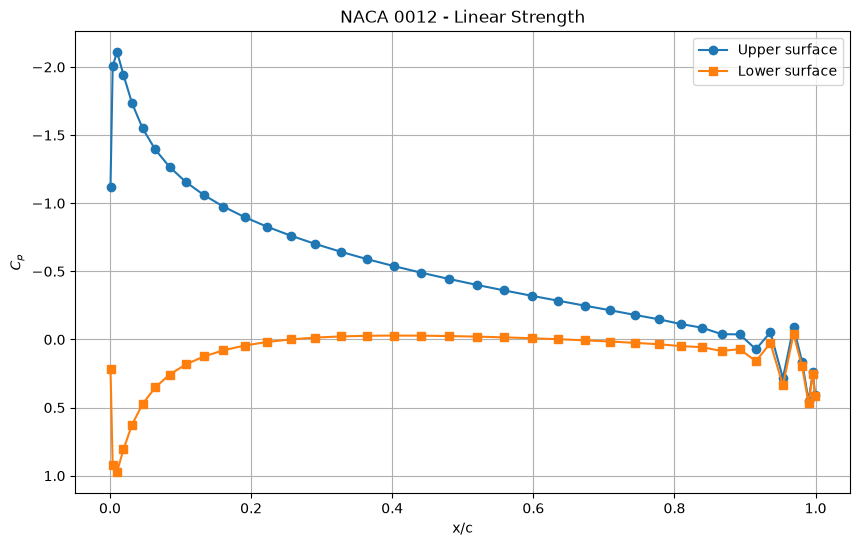

In [83]:
plot_separate_surfaces(result_0012_0,"NACA 0012 - Constant Strength")
plot_separate_surfaces(result_0012_1,"NACA 0012 - Linear Strength")

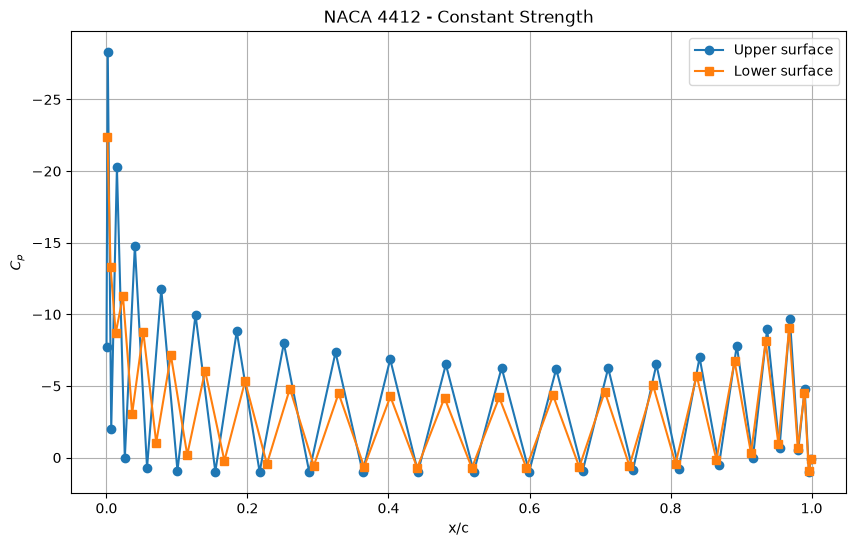

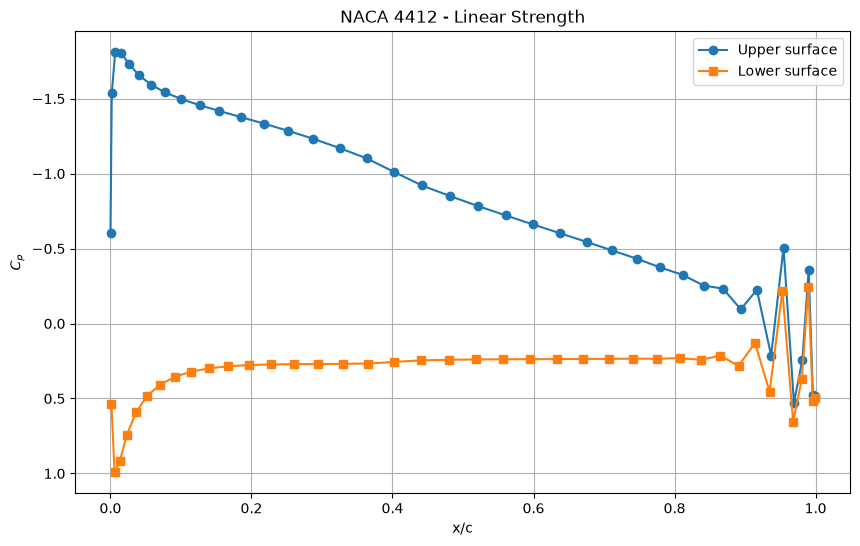

In [84]:
plot_separate_surfaces(result_4412_0,"NACA 4412 - Constant Strength")
plot_separate_surfaces(result_4412_1,"NACA 4412 - Linear Strength")

# Airfoil Convergence Study

A convergence study is performed to examine the effect of panel
number on the predicted lift coefficient.

The NACA 0012 and NACA 4412 airfoils are analysed using
20, 40, 80 and 160 panels.

The results from constant-strength and linear-strength
vortex panel methods are compared.

In [85]:
panel_counts = [40,80,120,160]

convergence_0012_0 = []
convergence_0012_1 = []

convergence_4412_0 = []
convergence_4412_1 = []

for N in panel_counts:

    # Generate airfoils
    x0012_temp, y0012_temp = naca4(0.0, 0.0, 0.12, n=N//2 + 1)
    x4412_temp, y4412_temp = naca4(0.04, 0.4, 0.12, n=N//2 + 1)

    # NACA 0012
    r0 = vortex_panel_method_0(x0012_temp, y0012_temp, V_inf, alpha)
    r1 = vortex_panel_method_1(x0012_temp, y0012_temp, V_inf, alpha)

    convergence_0012_0.append(r0["Cl"])
    convergence_0012_1.append(r1["Cl"])

    # NACA 4412
    r0 = vortex_panel_method_0(x4412_temp, y4412_temp, V_inf, alpha)
    r1 = vortex_panel_method_1(x4412_temp, y4412_temp, V_inf, alpha)

    convergence_4412_0.append(r0["Cl"])
    convergence_4412_1.append(r1["Cl"])


print("Panel count | NACA 0012 Constant | NACA 0012 Linear")
for i, N in enumerate(panel_counts):
    print(N, convergence_0012_0[i], convergence_0012_1[i])

print("\nPanel count | NACA 4412 Constant | NACA 4412 Linear")
for i, N in enumerate(panel_counts):
    print(N, convergence_4412_0[i], convergence_4412_1[i])

Panel count | NACA 0012 Constant | NACA 0012 Linear
40 0.6439047259338708 0.6062735795737143
80 0.6050667328823804 0.6052888999146758
120 0.6048691165184352 0.6046008872408228
160 0.604764835329934 0.6041932631121915

Panel count | NACA 4412 Constant | NACA 4412 Linear
40 1.1759573336474864 1.1227011956982647
80 1.1123805412558938 1.122486977079316
120 1.1264786299995435 1.1215551865806088
160 1.1229424784959585 1.1210006824251535


**Plot NACA 0012 convergence**

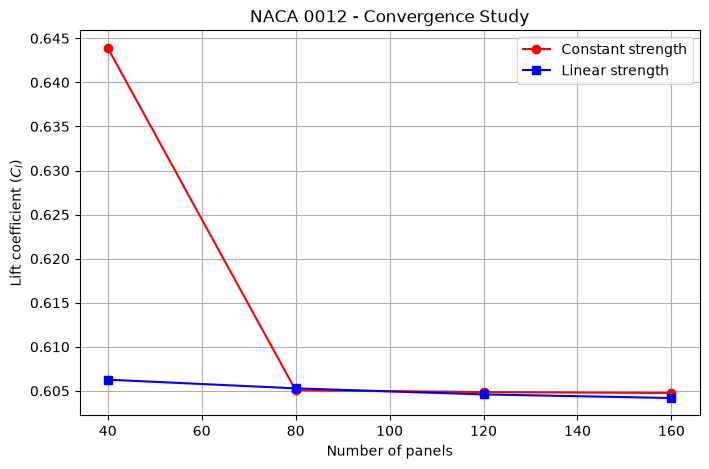

In [86]:
plt.figure(figsize=(8,5))
plt.plot(panel_counts, convergence_0012_0,'ro-', label="Constant strength")
plt.plot(panel_counts, convergence_0012_1,'bs-', label="Linear strength")
plt.xlabel("Number of panels")
plt.ylabel("Lift coefficient ($C_l$)")
plt.title("NACA 0012 - Convergence Study")
plt.grid(True,which="both")
plt.legend()
plt.show()

**Plot NACA 4412 convergence**

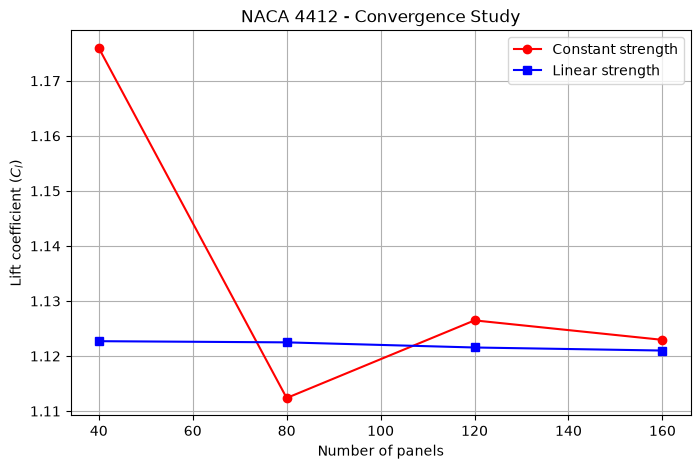

In [87]:
plt.figure(figsize=(8,5))
plt.plot(panel_counts, convergence_4412_0,'ro-', label="Constant strength")
plt.plot(panel_counts, convergence_4412_1,'bs-', label="Linear strength")
plt.xlabel("Number of panels")
plt.ylabel("Lift coefficient ($C_l$)")
plt.title("NACA 4412 - Convergence Study")
plt.grid()
plt.legend()
plt.show()

The convergence study was performed using NACA 0012 and NACA 4412 airfoils with different numbers of panels.

For NACA 0012, the constant-strength method showed considerable variation at lower panel counts. Its predicted lift coefficient approached approximately 0.605 as the number of panels increased.

The linear-strength method produced relatively stable results, with the lift coefficient remaining close to 0.605 for all panel counts considered.

For NACA 4412, the linear-strength method predicted lift coefficients close to 1.12. The constant-strength method showed greater variation, particularly at lower panel counts.

The results indicate that panel discretization influences the accuracy of the numerical solution. The linear-strength method demonstrated better stability for the cases investigated.

#  Effect of Panel Distribution

The accuracy of the vortex panel method depends not only on the number of panels but also on their distribution along the airfoil surface.

Two panel distributions are considered:

1. Uniform spacing: panel nodes are equally spaced along the chordwise coordinate.
2. Cosine spacing: panel nodes are concentrated near the leading and trailing edges.

Both distributions are compared using the same number of panels.

This function generates NACA airfoil coordinates using either uniform or cosine spacing.

In [88]:
import numpy as np

def naca4_distribution(m, p, t, n=41, spacing="cosine"):

    if spacing == "cosine":
        beta = np.linspace(0, np.pi, n)
        x = 0.5 * (1 - np.cos(beta))

    elif spacing == "uniform":
        x = np.linspace(0, 1, n)

    else:
        raise ValueError("Spacing must be 'uniform' or 'cosine'.")

    yt = 5 * t * (0.2969 * np.sqrt(x) - 0.1260 * x - 0.3516 * x**2 + 0.2843 * x**3 - 0.1036 * x**4)

    yc = np.zeros_like(x)
    dyc_dx = np.zeros_like(x)

    for i in range(n):
        if x[i] < p and p != 0:
            yc[i] = (m / p**2) * (2*p*x[i] - x[i]**2)
            dyc_dx[i] = (2*m / p**2) * (p - x[i])

        elif p != 0:
            yc[i] = (m / (1-p)**2) * ((1 - 2*p) + 2*p*x[i] - x[i]**2)
            dyc_dx[i] = (2*m / (1-p)**2) * (p - x[i])

    theta = np.arctan(dyc_dx)

    xu = x - yt * np.sin(theta)
    yu = yc + yt * np.cos(theta)

    xl = x + yt * np.sin(theta)
    yl = yc - yt * np.cos(theta)

    # Counter-clockwise closed contour: upper TE to LE to lower TE
    x_coords = np.concatenate((xu[::-1], xl[1:]))
    y_coords = np.concatenate((yu[::-1], yl[1:]))

    return x_coords, y_coords

In [89]:
# NACA 0012
x0012_uniform, y0012_uniform = naca4_distribution(0.0, 0.0, 0.12, n=41, spacing="uniform")
x0012_cosine, y0012_cosine = naca4_distribution(0.0, 0.0, 0.12, n=41, spacing="cosine")

# NACA 4412
x4412_uniform, y4412_uniform = naca4_distribution(0.04, 0.4, 0.12, n=41, spacing="uniform")
x4412_cosine, y4412_cosine = naca4_distribution(0.04, 0.4, 0.12, n=41, spacing="cosine")

print("Panels in each case:", len(x0012_uniform) - 1)

Panels in each case: 80


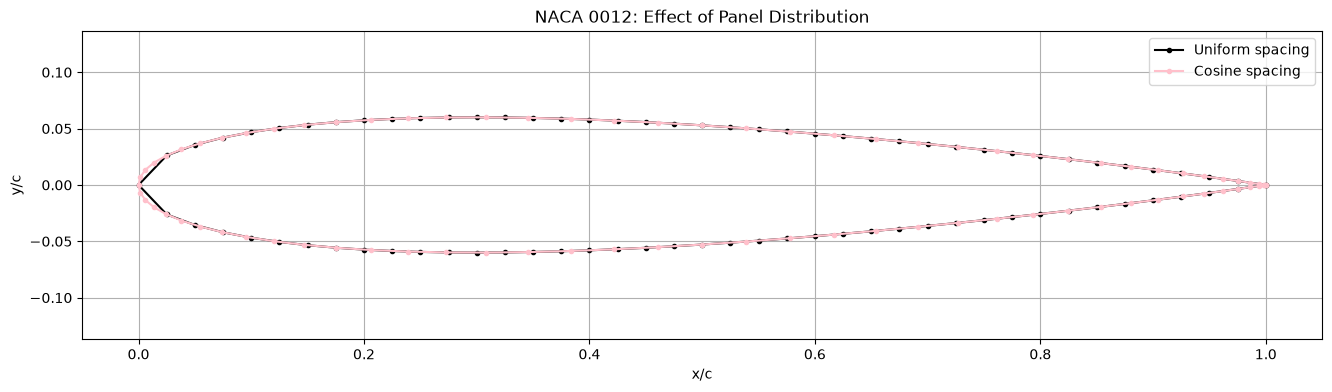

In [90]:
plt.figure(figsize=(16, 4))
plt.plot(x0012_uniform, y0012_uniform,"o-",markersize=3,label="Uniform spacing",color="black")
plt.plot(x0012_cosine, y0012_cosine,"o-",markersize=3,label="Cosine spacing",color="pink")
plt.xlabel("x/c")
plt.ylabel("y/c")
plt.title("NACA 0012: Effect of Panel Distribution")
plt.axis("equal")
plt.grid()
plt.legend()
plt.show()

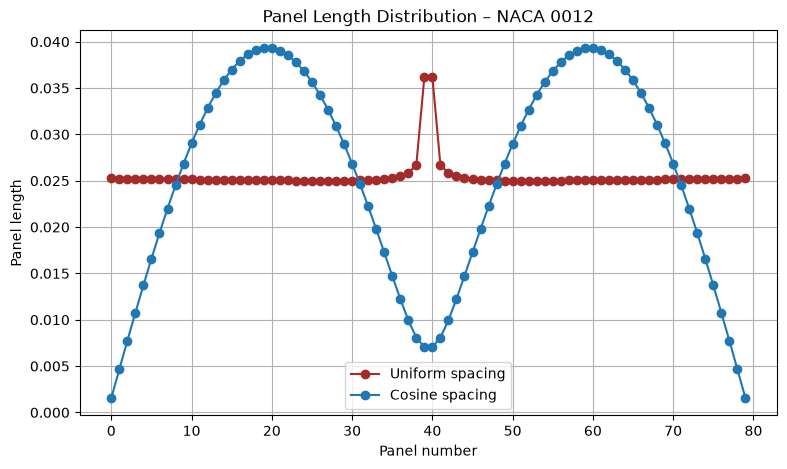

In [91]:
def calculate_panel_lengths(x, y):
    dx = np.diff(x)
    dy = np.diff(y)
    return np.sqrt(dx**2 + dy**2)

length_uniform = calculate_panel_lengths(x0012_uniform, y0012_uniform)
length_cosine = calculate_panel_lengths(x0012_cosine, y0012_cosine)

plt.figure(figsize=(9, 5))
plt.plot(length_uniform, "o-", label="Uniform spacing",color="brown")
plt.plot(length_cosine, "o-", label="Cosine spacing")
plt.xlabel("Panel number")
plt.ylabel("Panel length")
plt.title("Panel Length Distribution – NACA 0012")
plt.grid()
plt.legend()
plt.show()

- Uniform spacing has more evenly distributed panel nodes.

- Cosine spacing concentrates nodes near the leading and trailing edges.

- The panel-length plot shows how the two distributions differ.

In [92]:
N = 80
alpha = 5.0
Vinf = 1.0

# Generate NACA 0012
x_cos, y_cos = naca4_distribution(0, 0, 0.12, n=N//2 + 1, spacing="cosine")
x_uni, y_uni = naca4_distribution(0, 0, 0.12, n=N//2 + 1, spacing="uniform")
# Generate NACA 4412
x4412_cos, y4412_cos = naca4_distribution(0.04, 0.4, 0.12, n=N//2 + 1, spacing="cosine")
x4412_uni, y4412_uni = naca4_distribution(0.04, 0.4, 0.12, n=N//2 + 1, spacing="uniform")

# NACA 0012
r0012_cos_0 = vortex_panel_method_0(x_cos, y_cos, Vinf, alpha)
r0012_cos_1 = vortex_panel_method_1(x_cos, y_cos, Vinf, alpha)

r0012_uni_0 = vortex_panel_method_0(x_uni, y_uni, Vinf, alpha)
r0012_uni_1 = vortex_panel_method_1(x_uni, y_uni, Vinf, alpha)

# NACA 4412
r4412_cos_0 = vortex_panel_method_0(x4412_cos, y4412_cos, Vinf, alpha)
r4412_cos_1 = vortex_panel_method_1(x4412_cos, y4412_cos, Vinf, alpha)

r4412_uni_0 = vortex_panel_method_0(x4412_uni, y4412_uni, Vinf, alpha)
r4412_uni_1 = vortex_panel_method_1(x4412_uni, y4412_uni, Vinf, alpha)

# Lift Coefficients
print("NACA 0012")
print("Cosine - Constant:", r0012_cos_0["Cl"])
print("Cosine - Linear:", r0012_cos_1["Cl"])
print("Uniform - Constant:", r0012_uni_0["Cl"])
print("Uniform - Linear:", r0012_uni_1["Cl"])

print("\nNACA 4412")
print("Cosine - Constant:", r4412_cos_0["Cl"])
print("Cosine - Linear:", r4412_cos_1["Cl"])
print("Uniform - Constant:", r4412_uni_0["Cl"])
print("Uniform - Linear:", r4412_uni_1["Cl"])

NACA 0012
Cosine - Constant: 0.6050667328823804
Cosine - Linear: 0.6052888999146758
Uniform - Constant: 1.0437520742958373
Uniform - Linear: 0.6065577764910215

NACA 4412
Cosine - Constant: 1.1123805412558938
Cosine - Linear: 1.122486977079316
Uniform - Constant: 1.4078765424912218
Uniform - Linear: 1.1324859382657273


#### Effect of Panel Distribution

The effect of uniform and cosine panel spacing was investigated for NACA 0012 and NACA 4412 using 80 panels at an angle of attack of 5°.

For the linear-strength vortex panel method, the lift coefficient showed only a small variation between the two distributions. The constant-strength method showed a larger variation, particularly with uniform spacing.

Cosine spacing provided more consistent lift predictions in the present calculations. This is because cosine spacing concentrates panels near the leading and trailing edges, where the pressure and velocity gradients are generally higher.

Therefore, panel distribution has a significant influence on the numerical accuracy of the constant-strength method, while the linear-strength method showed better stability in this comparison.

# Effect of Airfoil Thickness

- The influence of airfoil thickness on the predictions of the vortex panel method is investigated.
- Three thickness ratios are considered for symmetric and cambered airfoils. 
- The angle of attack, free-stream velocity and panel distribution are kept constant to ensure a consistent comparison.

Symmetric Airfoils
Thickness | Constant Cl | Linear Cl
(6.0, np.float64(0.6167965945645373), np.float64(0.5643238499363924))
(9.0, np.float64(0.59552676324486), np.float64(0.591106072953275))
(12.0, np.float64(0.6050667328823804), np.float64(0.6052888999146758))
(15.0, np.float64(0.6191991675735515), np.float64(0.6141788285800963))
(18.0, np.float64(0.6338281355931734), np.float64(0.6335724827574499))

Cambered Airfoils
Thickness | Constant Cl | Linear Cl
(6.0, np.float64(1.0937552579473357), np.float64(-0.4388943696532307))
(9.0, np.float64(1.071652784055523), np.float64(1.0906199798454093))
(12.0, np.float64(1.1123805412558938), np.float64(1.122486977079316))
(15.0, np.float64(1.1484963517029896), np.float64(1.1528110170202717))
(18.0, np.float64(1.1762581934102823), np.float64(1.1844688549090912))


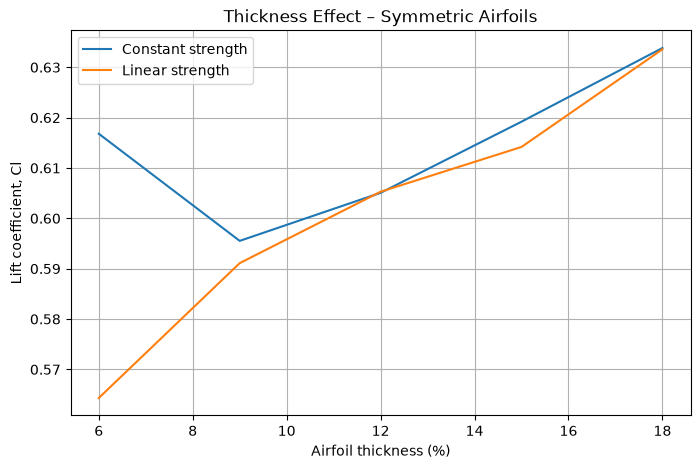

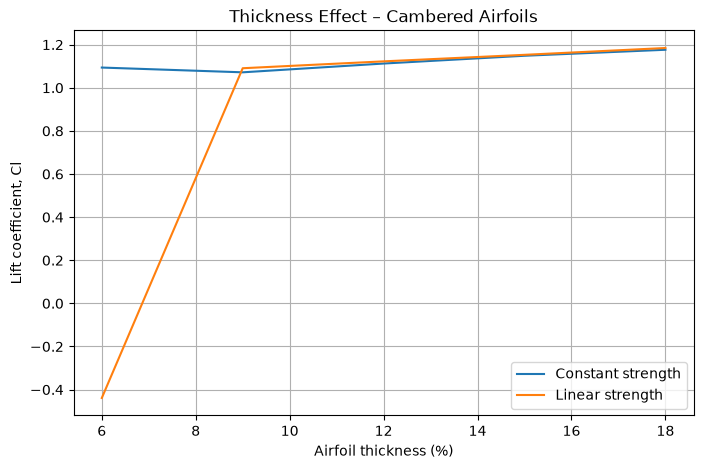

In [93]:
thicknesses = [0.06,0.09,0.12,0.15,0.18]

symmetric_results = []
cambered_results = []

N = 80
Vinf = 1.0
alpha = 5.0

for t in thicknesses:

    # Symmetric airfoils
    x, y = naca4_distribution(0, 0, t, n=N//2 + 1, spacing="cosine")
    result_0 = vortex_panel_method_0(x, y, Vinf, alpha)
    result_1 = vortex_panel_method_1(x, y, Vinf, alpha)

    symmetric_results.append((t * 100, result_0["Cl"], result_1["Cl"]))

    # Cambered airfoils
    x, y = naca4_distribution(0.04, 0.4, t, n=N//2 + 1, spacing="cosine")
    result_0 = vortex_panel_method_0(x, y, Vinf, alpha)
    result_1 = vortex_panel_method_1(x, y, Vinf, alpha)

    cambered_results.append((t * 100, result_0["Cl"], result_1["Cl"]))

print("Symmetric Airfoils")
print("Thickness | Constant Cl | Linear Cl")

for result in symmetric_results:
    print(result)

print("\nCambered Airfoils")
print("Thickness | Constant Cl | Linear Cl")

for result in cambered_results:
    print(result)

plt.figure(figsize=(8, 5))

plt.plot([r[0] for r in symmetric_results],[r[1] for r in symmetric_results],"-", label="Constant strength")
plt.plot([r[0] for r in symmetric_results],[r[2] for r in symmetric_results],"-", label="Linear strength")
plt.xlabel("Airfoil thickness (%)")
plt.ylabel("Lift coefficient, Cl")
plt.title("Thickness Effect – Symmetric Airfoils")
plt.grid()
plt.legend()
plt.show()


plt.figure(figsize=(8, 5))
plt.plot([r[0] for r in cambered_results],[r[1] for r in cambered_results],"-", label="Constant strength")
plt.plot([r[0] for r in cambered_results],[r[2] for r in cambered_results],"-", label="Linear strength")
plt.xlabel("Airfoil thickness (%)")
plt.ylabel("Lift coefficient, Cl")
plt.title("Thickness Effect – Cambered Airfoils")
plt.grid()
plt.legend()
plt.show()    

## References

1. H. Liu, Linear Strength Vortex Panel Method for NACA 4412 Airfoil, IOP Conference Series: Materials Science and Engineering, vol. 326, Art. no. 012016, 2018. doi: 10.1088/1757-899X/326/1/012016.
2. J. D. Anderson, Jr., Fundamentals of Aerodynamics, 7th ed. New York, NY, USA: McGraw-Hill, 2023.

## Acknowledgement of AI use

- Assistance from AI for plotting graphs and implementation of influence coefficients.
- Used as a debugger to find mistakes and errors and correct them.        